# 04 Test: the chosen models on the test period, once

**Purpose:** Evaluate the final model, chosen on the backtest only (`03_evaluate.ipynb`, section 9), on the test period (2024-10 to 2026-09), next to model 2 (the best model with all indicators, also chosen in `03`) and the simple rules. This is the only notebook that uses the test period.
**Input:** `../data/processed/asylum_clean.csv`, `routes_clean.csv`, `neighbours_clean.csv`, `conflict_clean.csv`, and `../output/tables/03_backtest_errors.csv` and `03_two_models.csv` (from `03_evaluate.ipynb`).
**Output:** `../data/processed/test_forecasts.csv`, `../output/tables/04_test_errors.csv` and `../output/figures/04_test_forecasts_h2.png`.

**The choice was made before the test** (notebook 209, Step 7): the linear regression on the series' own past. We do not change it after seeing the results below (notebook 209, Step 8).

**Timeline.** The group fixed the choice rule and chose the linear regression on 17 November 2026 (commit `c6a3976`), then ran the test once (commit `4f284f5`). The random walk, the neighbouring countries and the conflict index were added afterwards, on the backtest only. The rule was not changed, and it still chooses the linear regression (`03`, section 9), so the test result of the chosen model is the same as in the first run. Model 2 and the other extensions were built after that first test, so their test results are for information only.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso

np.random.seed(42)
plt.style.use("seaborn-v0_8-muted")

## 1. Load the whole series

For the first time, we use all 225 months, including the 24 months of the test period.

In [2]:
clean = pd.read_csv("../data/processed/asylum_clean.csv")
clean["month"] = pd.to_datetime(clean["month"])
clean = clean.set_index("month")

y = clean["applicants_total"].to_numpy(dtype=float)
log_y = clean["log_applicants"].to_numpy(dtype=float)
months = clean.index

last_backtest = int(np.where(months == pd.Timestamp("2024-09-01"))[0][0])
last_month = len(months) - 1
H_MAX = 3

print(clean["period"].value_counts())
print("Last backtest month:", months[last_backtest], "| last month:", months[last_month])

def load(path):
    data = pd.read_csv(path)
    data["month"] = pd.to_datetime(data["month"])
    return data.set_index("month")

log_routes = load("../data/processed/routes_clean.csv")["log_routes"].reindex(months).to_numpy(dtype=float)
log_neighbours = load("../data/processed/neighbours_clean.csv")["log_neighbours"].reindex(months).to_numpy(dtype=float)
conflict_index = load("../data/processed/conflict_clean.csv")["conflict_index"].reindex(months).to_numpy(dtype=float)

model_2 = pd.read_csv("../output/tables/03_two_models.csv").set_index("family").loc["all indicators", "model"]
print("Model 1: Linear regression | Model 2 (chosen in 03):", model_2)

period
backtest    141
training     60
test         24
Name: count, dtype: int64
Last backtest month: 2024-09-01 00:00:00 | last month: 2026-09-01 00:00:00
Model 1: Linear regression | Model 2 (chosen in 03): Ridge + all indicators


## 2. The models, exactly as in the backtest

We test the models chosen in `03_evaluate.ipynb` before looking at the test period, and nothing else (notebook 209, Step 8):

- **Model 1**, our final choice: the linear regression on the series' own past (`02b`).
- **Model 2**, the best model with all three indicators (`02c`): Ridge with the routes, the neighbouring countries and the conflict index, its lag chosen at each origin as in the backtest.
- **The 12-month average**, the best simple baseline of our plan, for the main comparison, and **the random walk** (the last known month).

The functions are copied from `02`, `02b` and `02c` without any change; first we check that the copy gives exactly the stored backtest forecasts at the last backtest origin.

In [3]:
def at(x, i):
    # Copied from 02c
    return x[i] if i >= 0 else np.nan

features = {   # copied from 02c
    "routes": {"routes_change_last_month": lambda t: log_routes[t - 1] - log_routes[t - 2],
               "routes_change_3_months": lambda t: log_routes[t - 1] - log_routes[t - 4]},
    "neighbours": {"neighbours_change_last_month": lambda t: log_neighbours[t - 1] - log_neighbours[t - 2],
                   "neighbours_change_3_months": lambda t: log_neighbours[t - 1] - log_neighbours[t - 4]},
}
LAGS = range(0, 13)

def block_features(block, L):
    if block == "conflict":
        return {"conflict_change_last_month": lambda t: at(conflict_index, t - L) - at(conflict_index, t - L - 1),
                "conflict_change_3_months": lambda t: at(conflict_index, t - L) - at(conflict_index, t - L - 3)}
    return features[block]

def make_table(h, parts, L=None):
    # Copied from 02c; with no indicator it is the table of 02b
    extra_features = {k: f for b in parts for k, f in block_features(b, L).items()}
    rows = []
    for t in range(12, len(log_y) - h):
        values = {name: f(t) for name, f in extra_features.items()}
        if any(np.isnan(v) for v in values.values()):
            continue
        rows.append({"t": t,
                     "change_last_month": log_y[t] - log_y[t - 1],
                     "change_month_before": log_y[t - 1] - log_y[t - 2],
                     "same_change_last_year": log_y[t + h - 12] - log_y[t - 12],
                     **values,
                     "calendar_month": months[t + h].month,
                     "target": log_y[t + h] - log_y[t]})
    table = pd.DataFrame(rows).set_index("t")
    dummies = pd.get_dummies(table["calendar_month"], prefix="month", drop_first=True).astype(float)
    names = ["change_last_month", "change_month_before", "same_change_last_year"] + list(extra_features)
    return pd.concat([table[names], dummies], axis=1), table["target"]

def make_model(name, alpha=None):
    # Copied from 02b
    if name == "Linear regression":
        return make_pipeline(StandardScaler(), LinearRegression())
    if name == "Ridge":
        return make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    return make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=10000))

alpha_grids = {"Linear regression": [None], "Ridge": [0.1, 1, 10, 100, 1000, 10000],
               "Lasso": [0.0001, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3]}

def validation_mse(name, alpha, X, target, T, h, n_blocks=2, block=12):
    # Copied from 02c
    first_row, last_row = X.index.min(), T - h
    mse_blocks = []
    for b in range(n_blocks):
        start = last_row - n_blocks * block + 1 + b * block
        valid_rows = list(range(start, start + block))
        train_rows = list(range(first_row, start - h + 1))
        model = make_model(name, alpha).fit(X.loc[train_rows], target.loc[train_rows])
        errors = target.loc[valid_rows].to_numpy() - model.predict(X.loc[valid_rows])
        mse_blocks.append(np.mean(errors ** 2))
    return np.mean(mse_blocks)

def choose_alpha(name, X, target, T, h):
    # Copied from 02c
    grid = alpha_grids[name]
    if len(grid) == 1:
        return grid[0]
    return grid[int(np.argmin([validation_mse(name, alpha, X, target, T, h) for alpha in grid]))]

def average_12(train_y, h_max):
    # Copied from 02: average of the last 12 known months, the same for every horizon
    return np.log(np.full(h_max, train_y[-12:].mean()))

name_2 = model_2.split(" + ")[0]                         # Ridge, Lasso or Linear regression
parts_2 = ["routes", "neighbours", "conflict"]
tables_1 = {h: make_table(h, []) for h in range(1, H_MAX + 1)}
tables_2 = {(h, L): make_table(h, parts_2, L) for h in range(1, H_MAX + 1) for L in LAGS}

def choose_lag(T, h):
    # Copied from 02c: only lags whose months exist at the origin T can be chosen
    scores = {L: validation_mse("Linear regression", None, *tables_2[(h, L)], T, h) for L in LAGS if T in tables_2[(h, L)][0].index}
    return min(scores, key=scores.get)

def regression_forecast(name, X, target, t, h):
    # one forecast of log applications at origin t, fitted on the rows whose target is known at t
    train_rows = list(range(X.index.min(), t - h + 1))
    assert max(train_rows) + h <= t                       # no training target after the origin
    alpha = choose_alpha(name, X, target, t, h)
    model = make_model(name, alpha).fit(X.loc[train_rows], target.loc[train_rows])
    return log_y[t] + model.predict(X.loc[[t]])[0]

def forecast_2(t, h):
    L = choose_lag(t, h)
    return regression_forecast(name_2, *tables_2[(h, L)], t, h), L

# Check the copy at the last backtest origin (2024-08, h = 1)
stored = pd.concat([pd.read_csv("../data/processed/backtest_forecasts_regression.csv"),
                    pd.read_csv("../data/processed/backtest_forecasts_indicator.csv")])
t0 = last_backtest - 1
s = stored[(stored["origin"] == str(months[t0].date())) & (stored["h"] == 1)].set_index("model")["forecast_log"]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    assert np.isclose(regression_forecast("Linear regression", *tables_1[1], t0, 1), s["Linear regression"])
    assert np.isclose(forecast_2(t0, 1)[0], s[model_2])
print("The copied functions reproduce the stored backtest forecasts of both models.")

The copied functions reproduce the stored backtest forecasts of both models.


## 3. Forecasts for the test period

We continue the backtest into the test period with the same rule: at each origin, the models are fitted on **all months known at that origin and nothing after it**, and we forecast $h = 1, 2, 3$. The origins go from September 2024 (the last backtest month) to August 2026. So the forecasts for, say, March 2026 are made with the months up to December 2025 ($h = 3$), January 2026 ($h = 2$) or February 2026 ($h = 1$), as a planner would have had them.

This is the time-series version of "refit on all training data, then test" (notebook 209, Step 8): there is no single refit, because in practice the model is refitted every month when a new number arrives. We expect 24 forecasts for $h = 1$, 23 for $h = 2$ and 22 for $h = 3$ per model.

In [4]:
rows, lags_2 = [], []
for t in range(last_backtest, last_month):          # origins 2024-09 to 2026-08
    for h in range(1, H_MAX + 1):
        target_pos = t + h
        if target_pos > last_month:
            continue
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            forecast_lr = regression_forecast("Linear regression", *tables_1[h], t, h)
            forecast_m2, L = forecast_2(t, h)
        lags_2.append({"origin": months[t], "h": h, "lag": L})
        logs = {"Linear regression": forecast_lr, model_2: forecast_m2,
                "12-month average": average_12(y[: t + 1], H_MAX)[h - 1], "Random walk": log_y[t]}
        for name, forecast_log in logs.items():
            rows.append({"model": name, "origin": months[t], "month": months[target_pos], "h": h,
                         "forecast_log": forecast_log, "actual_log": log_y[target_pos],
                         "forecast": np.exp(forecast_log), "actual": y[target_pos]})

test_forecasts = pd.DataFrame(rows)
print(test_forecasts.groupby(["model", "h"]).size().unstack())
print()
print("All forecast months in the test period:", (test_forecasts["month"] >= pd.Timestamp("2024-10-01")).all())
print("All forecast months after their origin:", (test_forecasts["month"] > test_forecasts["origin"]).all())
print("Missing or infinite forecasts:", (~np.isfinite(test_forecasts["forecast_log"])).sum())
lags_2 = pd.DataFrame(lags_2)
print("Lag of the conflict index chosen at the test origins (model 2, h = 2):", lags_2[lags_2["h"] == 2]["lag"].tolist())

h                        1   2   3
model                             
12-month average        24  23  22
Linear regression       24  23  22
Random walk             24  23  22
Ridge + all indicators  24  23  22

All forecast months in the test period: True
All forecast months after their origin: True
Missing or infinite forecasts: 0
Lag of the conflict index chosen at the test origins (model 2, h = 2): [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


**What we see.** Each model has 24 forecasts for $h = 1$, 23 for $h = 2$ and 22 for $h = 3$, as expected. All forecast months lie in the test period and after their origin, and no forecast is missing. Together with the `assert` in the loop, this shows that each forecast used only the months known at its origin.

## 4. Test errors

The same two error measures as in `03_evaluate.ipynb`: the MAE in persons (main) and the RMSE in logs.

In [5]:
test_forecasts["abs_error"] = (test_forecasts["actual"] - test_forecasts["forecast"]).abs()
test_forecasts["sq_error_log"] = (test_forecasts["actual_log"] - test_forecasts["forecast_log"]) ** 2

grouped = test_forecasts.groupby(["model", "h"])
test_errors = pd.DataFrame({
    "MAE (persons)": grouped["abs_error"].mean(),
    "RMSE (log)": np.sqrt(grouped["sq_error_log"].mean()),
    "forecasts": grouped["abs_error"].size(),
}).reset_index()
test_errors.to_csv("../output/tables/04_test_errors.csv", index=False)
test_errors.round(3)

,model,h,MAE (persons),RMSE (log),forecasts
0,12-month average,1,297.309,0.177,24
1,12-month average,2,331.286,0.191,23
2,12-month average,3,359.299,0.204,22
3,Linear regression,1,149.287,0.098,24
4,Linear regression,2,187.966,0.112,23
5,Linear regression,3,217.125,0.144,22
6,Random walk,1,187.083,0.104,24
7,Random walk,2,269.130,0.161,23
8,Random walk,3,358.409,0.213,22
9,Ridge + all indicators,1,129.775,0.086,24


**What we see.** At $h = 2$ the chosen linear regression has an MAE of 188 persons, model 2 (Ridge with all indicators) 183, the random walk 269 and the 12-month average 331. Model 2 is also a little better at $h = 1$ (130 against 149) and $h = 3$ (203 against 217). The test errors are about half the backtest errors, because the test months are calm (see below).

### The main comparison at $h = 2$

In [6]:
h2 = test_errors[test_errors["h"] == 2].set_index("model")
mae_lr = h2.loc["Linear regression", "MAE (persons)"]
for other in ["12-month average", "Random walk", model_2]:
    mae_o = h2.loc[other, "MAE (persons)"]
    print(f"Linear regression {mae_lr:.1f} against {other} {mae_o:.1f}: {100 * (1 - mae_lr / mae_o):.0f}% lower MAE, "
          f"{100 * (1 - h2.loc['Linear regression', 'RMSE (log)'] / h2.loc[other, 'RMSE (log)']):.0f}% lower RMSE (log)")
print("Success rule of our plan (at least 10% lower MAE than the best simple baseline):",
      mae_lr <= 0.9 * h2.loc["12-month average", "MAE (persons)"])
print(f"For comparison, average actual number of applications in these months: {test_forecasts[test_forecasts['h'] == 2]['actual'].mean():.0f}")

Linear regression 188.0 against 12-month average 331.3: 43% lower MAE, 41% lower RMSE (log)
Linear regression 188.0 against Random walk 269.1: 30% lower MAE, 30% lower RMSE (log)
Linear regression 188.0 against Ridge + all indicators 183.3: -3% lower MAE, -2% lower RMSE (log)
Success rule of our plan (at least 10% lower MAE than the best simple baseline): True
For comparison, average actual number of applications in these months: 1982


**What we see.** The linear regression has a **43% lower MAE** than the 12-month average (188 against 331) and 41% lower RMSE (log); against the random walk 30% lower. The success rule of our plan (at least 10% lower MAE than the best simple baseline) is met. Model 2 is 5 persons per month better on the test (183 against 188, 3%), the opposite of the backtest (372 against 358). For comparison, there were on average about 1,980 applications per month in these test months.

## 5. Test against backtest

How do the test errors compare with the backtest errors of the same models (from `03_evaluate.ipynb`)? The backtest error of the chosen model is a little too optimistic, because it won the comparison (notebook 108b). The two periods also differ in how hard they are: we put the average number of applications next to the errors.

In [7]:
backtest = pd.read_csv("../output/tables/03_backtest_errors.csv").set_index("model")
comparison = pd.DataFrame(index=["Linear regression", model_2, "12-month average", "Random walk"])
for h in [1, 2, 3]:
    comparison[f"backtest MAE h={h}"] = backtest.loc[comparison.index, f"MAE h={h}"]
    comparison[f"test MAE h={h}"] = [test_errors[(test_errors["model"] == m) & (test_errors["h"] == h)]["MAE (persons)"].iloc[0]
                                     for m in comparison.index]
print(comparison.round(0))
print()
level = clean.groupby("period")["applicants_total"].agg(["mean", "std"]).round(0)
print("Applications per month in each period:")
print(level)

                        backtest MAE h=1  test MAE h=1  backtest MAE h=2  \
Linear regression                  256.0         149.0             358.0   
Ridge + all indicators             255.0         130.0             372.0   
12-month average                   487.0         297.0             528.0   
Random walk                        259.0         187.0             379.0   

                        test MAE h=2  backtest MAE h=3  test MAE h=3  
Linear regression              188.0             452.0         217.0  
Ridge + all indicators         183.0             485.0         203.0  
12-month average               331.0             558.0         359.0  
Random walk                    269.0             487.0         358.0  

Applications per month in each period:
            mean    std
period                 
backtest  1852.0  888.0
test      2008.0  338.0
training  1678.0  561.0


**What we see.** The test errors are much smaller than the backtest errors (188 against 358 for the linear regression at $h = 2$), for all models. The reason is the period, not the models: in the test months the applications varied much less (standard deviation 338 against 888 in the backtest), with no crisis like 2015-16 or 2022. The two regressions are close together in both periods, ahead of the random walk and the 12-month average; which of the two is ahead changes from backtest to test.

## 6. The forecasts two months ahead, month by month

The table shows what a planner would have seen: for each month of the test period, the forecast made two months earlier and the actual number.

In [8]:
h2_forecasts = test_forecasts[test_forecasts["h"] == 2]
monthly = h2_forecasts.pivot(index="month", columns="model", values="forecast")[["12-month average", "Linear regression", model_2]].round(0)
monthly.insert(0, "Actual", h2_forecasts.groupby("month")["actual"].first())
monthly["error of the linear regression"] = monthly["Linear regression"] - monthly["Actual"]
monthly

model,Actual,12-month average,Linear regression,Ridge + all indicators,error of the linear regression
month,,,,,
2024-11-01,2320.0,2485.0,2480.0,2531.0,160.0
2024-12-01,1850.0,2409.0,2179.0,2145.0,329.0
2025-01-01,1910.0,2341.0,2118.0,2127.0,208.0
2025-02-01,1765.0,2308.0,1702.0,1738.0,-63.0
2025-03-01,1825.0,2237.0,1642.0,1625.0,-183.0
2025-04-01,1890.0,2180.0,1573.0,1666.0,-317.0
2025-05-01,2020.0,2134.0,1723.0,1838.0,-297.0
2025-06-01,2210.0,2102.0,2270.0,2094.0,60.0
2025-07-01,2480.0,2074.0,2441.0,2434.0,-39.0


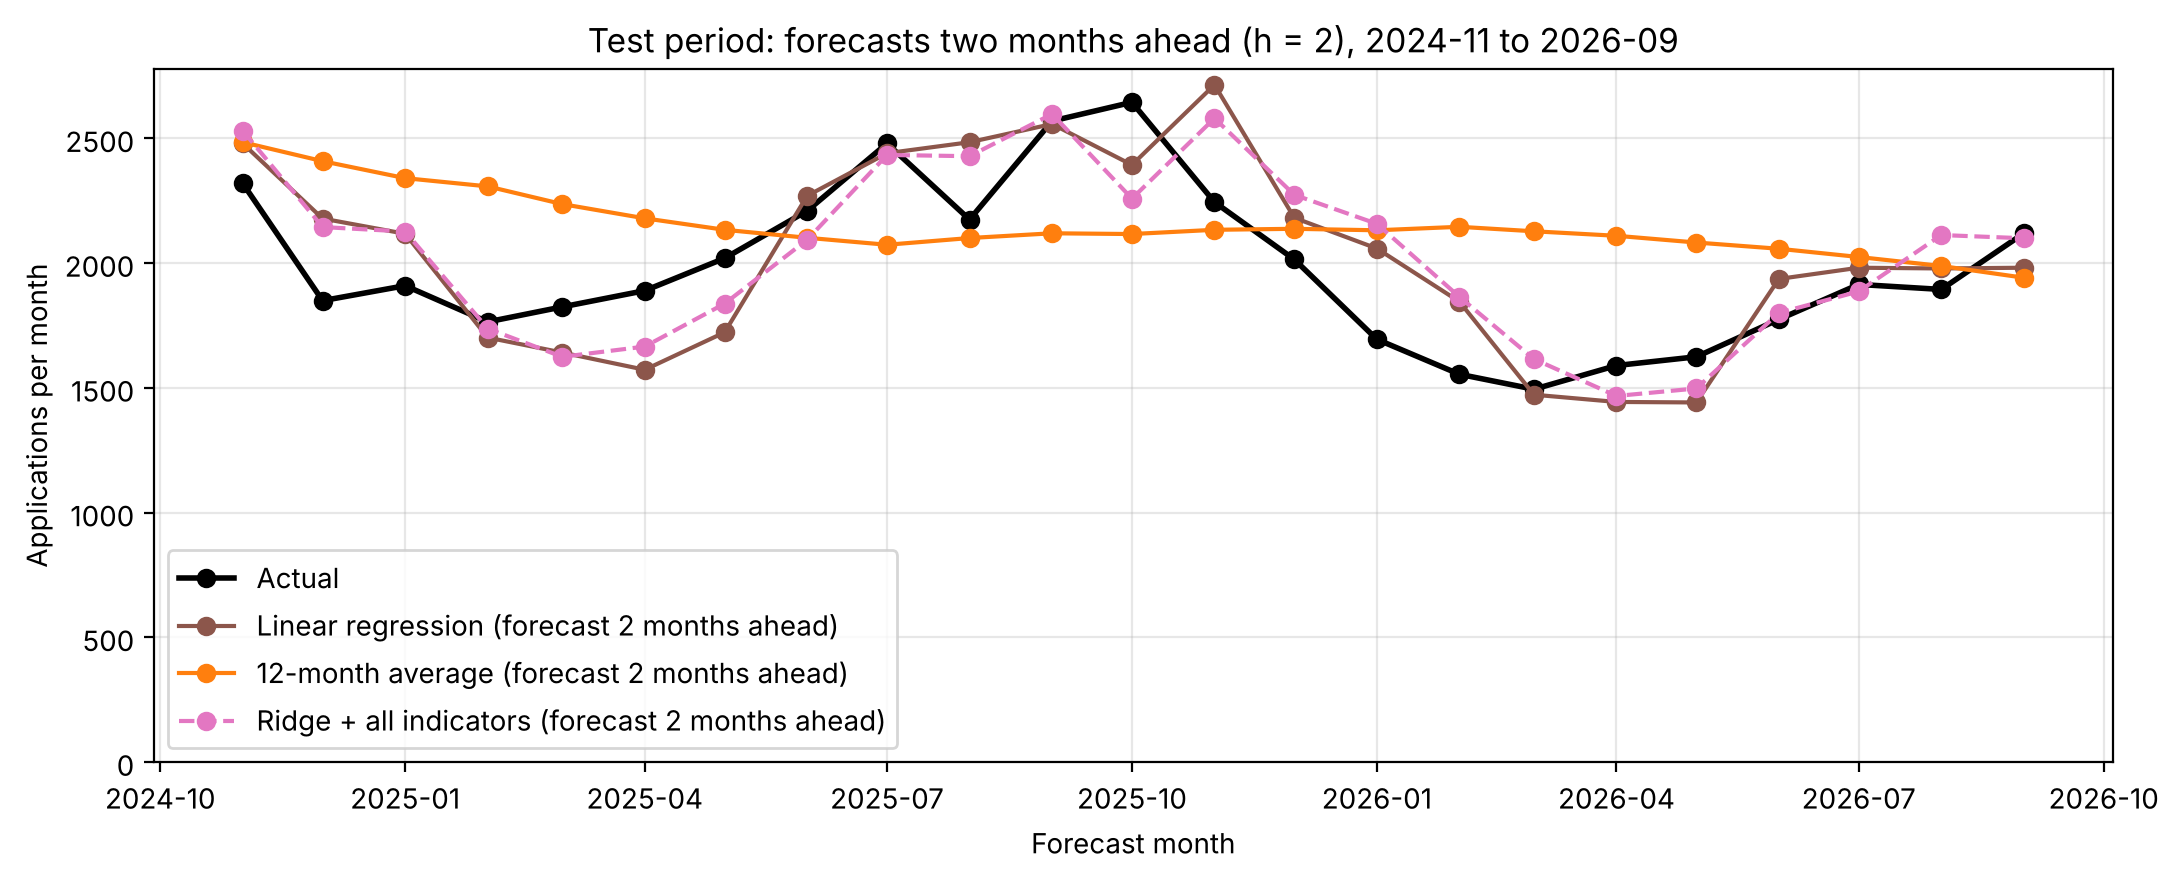

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly.index, monthly["Actual"], color="black", linewidth=2, marker="o", label="Actual")
ax.plot(monthly.index, monthly["Linear regression"], color=plt.cm.tab10(5), marker="o", label="Linear regression (forecast 2 months ahead)")
ax.plot(monthly.index, monthly["12-month average"], color=plt.cm.tab10(1), marker="o", label="12-month average (forecast 2 months ahead)")
ax.plot(monthly.index, monthly[model_2], color=plt.cm.tab10(6), marker="o", linestyle="--", label=f"{model_2} (forecast 2 months ahead)")
ax.set_title("Test period: forecasts two months ahead (h = 2), 2024-11 to 2026-09")
ax.set_xlabel("Forecast month")
ax.set_ylabel("Applications per month")
ax.set_ylim(bottom=0)
ax.legend(loc="lower left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/04_test_forecasts_h2.png")
plt.show()

**What we see.** The forecasts of the linear regression and of model 2 follow the actual numbers closely and are close to each other (on average 79 persons apart, at most 175); model 2 is closer in 11 of the 23 months. Both miss the largest month-to-month jumps by one or two months, as any model on past values does. At every test origin, model 2 chose lag 0 for the conflict index.

## 7. Save the test forecasts

In [10]:
test_forecasts.drop(columns=["abs_error", "sq_error_log"]).to_csv("../data/processed/test_forecasts.csv", index=False)
print("Saved", test_forecasts.shape[0], "test forecasts")

Saved 276 test forecasts


## Summary

- **Test period:** October 2024 to September 2026, used once; 23 forecasts per model at $h = 2$, all made with the months known at their origin.
- **Chosen model (linear regression):** MAE 188 persons at $h = 2$, **43% lower** than the 12-month average (331) and 30% lower than the random walk (269). The success rule is met.
- **Model 2 (Ridge with all indicators):** MAE 183, 3% lower than the linear regression on the test, after being 4% higher in the backtest; the difference is 5 persons per month over 23 months, small against the 12 backtest years.
- **Test errors are smaller than backtest errors** because the test months were calm, not because the models became better.
- The choice made before the test stays: the linear regression on the series' own past (notebook 209, Step 8).